# Data-driven and physics-informed neural networks
Reproducible data preparation, grouped five-fold selection, full-training refitting, and final evaluation. Only x1–x9 enter the networks. IDs and predictor groups are metadata. The academic report is maintained separately. OpenAI Codex assisted with implementation and explanatory text; the author must review and disclose this contribution.


In [ ]:
%pip install -q numpy==2.3.5 pandas==2.2.3 scikit-learn==1.8.0 xlrd==2.0.1 matplotlib==3.10.8
%pip install -q torch==2.14.1 --index-url https://download.pytorch.org/whl/cpu


## 1. Data source and output directories
Upload the supplied Database.xls in Colab, or set WORKBOOK to a local path. Outputs are separated by analysis stage. Colab runtime files are temporary; download the output archive before ending the session.

If Colab requests a runtime restart after dependency installation, restart and rerun the notebook in order.


In [ ]:
from pathlib import Path

# Change this path when running outside Colab.
WORKBOOK = Path("Database.xls")
if not WORKBOOK.is_file():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError("Set WORKBOOK to your Database.xls path.") from exc
    uploaded = files.upload()
    if "Database.xls" not in uploaded:
        raise FileNotFoundError("Please upload the supplied Database.xls workbook.")
    del uploaded

OUTPUT_ROOT = Path("outputs")
for folder in [OUTPUT_ROOT / "preprocessing", OUTPUT_ROOT / "partitions", OUTPUT_ROOT / "data_driven_search"]:
    folder.mkdir(parents=True, exist_ok=True)

## 2. Inspect and prepare the data
Read the second header row, validate numeric values and IDs, retain every observation, and identify exact repeated predictor combinations. Standardization is defined here but remains unfitted. The initial target representation is log10(y); its inverse yields positive predictions. This is separate from the RMSLE metric definition. Original numerical units must be used in the physics equation.

In [ ]:
"""Inspect the supplied workbook without fitting transforms on held-out data."""
from pathlib import Path
import argparse
import json

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

FEATURES = [f"x{i}" for i in range(1, 10)]


def load_workbook(path):
    # Row 1 contains merged section headings; row 2 contains feature names.
    df = pd.read_excel(path, sheet_name="sorted all", header=1)
    if df.shape[1] != 11 or list(df.columns[1:]) != FEATURES + ["y"]:
        raise ValueError("Unexpected workbook columns; inspect the source header.")
    df.columns = ["ID"] + FEATURES + ["y"]
    df = df.apply(pd.to_numeric, errors="raise")
    if not np.isfinite(df.to_numpy()).all():
        raise ValueError("Missing or nonfinite values require explicit investigation.")
    if df.ID.duplicated().any() or (df.ID % 1 != 0).any():
        raise ValueError("IDs must be unique integers.")
    if (df[["x1", "x2", "y"]] <= 0).any().any():
        raise ValueError("The physical relation and log target require positive x1, x2, y.")
    df["ID"] = df.ID.astype("int64")
    # Exact predictor matches share an ID regardless of their observed target.
    df["predictor_group"] = df.groupby(FEATURES, sort=True, dropna=False).ngroup()
    return df


class FoldPreprocessor:
    """Fit only on a fold's training rows; preserve original units separately.

    Raw features are standardized, including features that can be zero.
    The target is represented as log10(y), with no learned target statistics.
    """

    def __init__(self):
        self.scaler = StandardScaler()

    def fit(self, training_rows):
        self.scaler.fit(training_rows[FEATURES])
        return self

    def transform_inputs(self, rows):
        return self.scaler.transform(rows[FEATURES])

    @staticmethod
    def transform_target(rows):
        values = rows["y"].to_numpy(dtype=float)
        if not np.isfinite(values).all() or (values <= 0).any():
            raise ValueError("Log target requires finite positive values.")
        return np.log10(values)

    @staticmethod
    def inverse_target(log_predictions):
        with np.errstate(over="raise", under="raise", invalid="raise"):
            predictions = np.power(10.0, np.asarray(log_predictions, dtype=float))
        if not np.isfinite(predictions).all() or (predictions <= 0).any():
            raise ValueError("Predictions must be finite and strictly positive.")
        return predictions


def prepare_preprocessing(path, output):
    df = load_workbook(path)
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    groups = df.groupby("predictor_group")
    audit = {
        # Total number of observations.
        "samples": len(df),
        # Names of the nine model input columns.
        "predictors": FEATURES,
        # Total number of missing cells across all columns.
        "missing_cells": int(df.isna().sum().sum()),
        # Total number of NaN or positive/negative infinity cells.
        "nonfinite_cells": int((~np.isfinite(df.to_numpy())).sum()),
        # Number of distinct combinations of all nine input features.
        "unique_predictor_groups": int(groups.ngroups),
        # All rows sharing their feature combination with another row, including the first.
        "rows_in_repeated_predictor_groups": int(df.duplicated(FEATURES, keep=False).sum()),
        # Rows repeating a feature combination after its first occurrence.
        "extra_rows_with_repeated_predictors": int(df.duplicated(FEATURES).sum()),
        # Feature groups containing more than one distinct target value.
        "groups_with_different_targets": int((groups.y.nunique() > 1).sum()),
        # Extra rows with identical features AND target, ignoring sample ID.
        "repeated_records_excluding_id": int(df.duplicated(FEATURES + ["y"]).sum()),
        # No observations are removed by this preprocessing step.
        "removed_rows": 0,
        # Scaling is deferred until training partitions have been constructed.
        "scaling_fitted": False,
    }
    df.to_csv(output / "validated_data.csv", index=False, float_format="%.17g")
    df.describe().to_csv(output / "descriptive_statistics.csv")
    repeated = df[df.duplicated(FEATURES, keep=False)].sort_values(["predictor_group", "ID"])
    repeated.to_csv(output / "repeated_predictors.csv", index=False, float_format="%.17g")
    (output / "data_audit.json").write_text(json.dumps(audit, indent=2) + "\n")
    print(json.dumps(audit, indent=2))




In [ ]:
prepare_preprocessing(WORKBOOK, OUTPUT_ROOT / "preprocessing")
display(load_workbook(WORKBOOK).head())

## 3. Shared grouped partitions
Use seed 42. Hold out 20% of distinct predictor groups, then create five shuffled group folds within training. Keep targets out of partition construction. A validation_fold of k means the row is held out in CV round k; train that round on the other four folds. Test rows have no fold. Reuse the saved assignments for both models. Fit a fresh scaler on fitting rows only in each round; do not fit on validation or test rows.

In [ ]:
"""Save shared, group-disjoint holdout and five-fold assignments (seed 42)."""
import argparse
import json
from pathlib import Path

import pandas as pd
from sklearn.model_selection import GroupKFold, GroupShuffleSplit



SEED = 42


def create_assignments(df):
    # The fraction applies to predictor groups, so row counts may depart from 80/20.
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
    train_indices, test_indices = next(splitter.split(df, groups=df.predictor_group))
    assignments = df[["ID", "predictor_group"]].copy()
    assignments["partition"] = "train"
    assignments.loc[test_indices, "partition"] = "test"
    # Fold numbers indicate when a training row is used for validation.
    # Test rows have no validation fold and must never enter cross-validation.
    assignments["validation_fold"] = pd.Series(pd.NA, index=df.index, dtype="Int64")
    training = df.iloc[train_indices]
    folds = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    for fold, (_, validation_indices) in enumerate(
        folds.split(training, groups=training.predictor_group), start=1
    ):
        assignments.loc[training.index[validation_indices], "validation_fold"] = fold
    validate_assignments(df, assignments)
    return assignments


def validate_assignments(df, assignments):
    if len(assignments) != len(df) or not assignments.ID.equals(df.ID):
        raise ValueError("Assignments must preserve every sample ID exactly once.")
    if assignments.groupby("predictor_group").partition.nunique().max() != 1:
        raise ValueError("A predictor group crosses the train/test boundary.")
    training = assignments[assignments.partition == "train"]
    testing = assignments[assignments.partition == "test"]
    if training.validation_fold.isna().any() or testing.validation_fold.notna().any():
        raise ValueError("Only training samples must have validation fold assignments.")
    if set(training.validation_fold) != set(range(1, 6)):
        raise ValueError("Exactly five nonempty validation folds are required.")
    if training.groupby("predictor_group").validation_fold.nunique().max() != 1:
        raise ValueError("A predictor group crosses validation folds.")


def prepare_partitions(workbook, output):
    df = load_workbook(workbook)
    assignments = create_assignments(df)
    # Recreate assignments to verify deterministic behavior without using targets.
    pd.testing.assert_frame_equal(assignments, create_assignments(df))
    training = assignments[assignments.partition == "train"]
    testing = assignments[assignments.partition == "test"]
    summary = {
        "seed": SEED,
        "holdout_method": "GroupShuffleSplit(test_size=0.2)",
        "fold_method": "GroupKFold(n_splits=5, shuffle=True)",
        "group_definition": "Exact equality of x1 through x9; target excluded",
        "total_samples": len(df),
        "training_samples": len(training),
        "testing_samples": len(testing),
        "training_fraction": len(training) / len(df),
        "testing_fraction": len(testing) / len(df),
        "training_groups": training.predictor_group.nunique(),
        "testing_groups": testing.predictor_group.nunique(),
        "folds": [
            {"fold": fold,
             "training_samples": int((training.validation_fold != fold).sum()),
             "validation_samples": int((training.validation_fold == fold).sum())}
            for fold in range(1, 6)
        ],
        "checks": {
            "all_samples_assigned_once": True,
            "no_train_test_group_overlap": True,
            "no_cross_fold_group_overlap": True,
            "reproducible_assignments": True,
        },
        "scaling_fitted": False,
        "models_trained": False,
    }
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    assignments.to_csv(output / "partition_assignments.csv", index=False)
    (output / "partition_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
    print(json.dumps(summary, indent=2))




In [ ]:
assignment_path = OUTPUT_ROOT / "partitions/partition_assignments.csv"
if not assignment_path.exists():
    prepare_partitions(WORKBOOK, OUTPUT_ROOT / "partitions")
else:
    print("Reusing saved partition assignments; their integrity is checked before training.")
display(pd.read_csv(assignment_path).head())


## 4. Data-driven search design

Use identical saved folds; fit every transform on fitting rows only. Test data are excluded.

| Hyperparameter | Range | Reason |
|---|---|---|
| Hidden layers; width | 1–3; 16, 32, 64 | Explore modest capacities for nine inputs. |
| Activation | ReLU, tanh | Compare piecewise-linear and smooth mappings. |
| Learning rate | 0.0003, 0.001, 0.003 | Tenfold range around a conventional Adam rate. |
| Batch size | 32, 64, 128 | Compare update frequency and averaging. |
| L2 | 0, 1e-5, 1e-4, 1e-3 | Test increasingly strong regularization. |
| Selected input logs | Off, on | Compress positive x1, x2, x4, x5, x6; especially wide-ranging x2 and x4. |

Standardization follows either input representation. The target is log10(y); outputs are inverted as 10**prediction without clipping. Train on mean squared log-target error plus L2 on weights only. Adam uses β=(0.9, 0.999), ε=1e-7; hidden initialization is He for ReLU or Xavier with tanh gain, with Xavier output weights and zero biases.

Sample **20 of 1,296 combinations without replacement**, seed 42: **100 fold fits**. Fold seeds are 42 + fold number; CPU execution uses one thread and deterministic algorithms. Early stopping uses validation RMSLE, maximum 1,000 epochs, patience 50, and min_delta=1e-5. Retain the absolute minimum-score checkpoint; min_delta controls patience only.

RMSLE = sqrt(mean((log10(1 + predicted_y) − log10(1 + y))²)); this differs from log-target RMSE. Select the lowest mean across five folds; report sample standard deviation (ddof=1). Final-refit duration is the median selected best epoch. The search is budget-limited, and selection scores are not independent test estimates.


In [ ]:
SEARCH_CONFIG = {'seed': 42, 'n_configs': 20, 'n_folds': 5, 'search_strategy': 'random_without_replacement', 'selection_metric': 'mean_validation_rmsle_base10_log1p', 'target_transform': 'log10', 'log_features': ['x1', 'x2', 'x4', 'x5', 'x6'], 'optimizer': {'name': 'adam', 'epsilon': 1e-07, 'beta_1': 0.9, 'beta_2': 0.999}, 'training': {'max_epochs': 1000, 'patience': 50, 'min_delta': 1e-05}, 'search_space': {'n_layers': [1, 2, 3], 'width': [16, 32, 64], 'activation': ['relu', 'tanh'], 'learning_rate': [0.0003, 0.001, 0.003], 'batch_size': [32, 64, 128], 'l2': [0.0, 1e-05, 0.0001, 0.001], 'log_inputs': [True, False]}}

# Save the exact experiment settings before executing any training runs.
config_directory = Path("configs")
config_directory.mkdir(exist_ok=True)
(config_directory / "data_driven_search.json").write_text(json.dumps(SEARCH_CONFIG, indent=2) + "\n")
print(json.dumps(SEARCH_CONFIG, indent=2))

## 5. Cross-validation implementation
The implementation records every sampled candidate, fold checkpoint, fitted scaler statistics, per-epoch history, out-of-fold predictions, elapsed time, and software versions. Completed fold fits can be resumed only when the experiment manifest matches. If changing code, data, or settings, use a new output directory. Checkpoints contain fold models and are not final models refitted on all training observations.

In [ ]:
"""Reproducible five-fold random search; the test partition is never evaluated."""
import argparse
import copy
import hashlib
import itertools
import json
import platform
import random
import time
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from sklearn.preprocessing import StandardScaler





def rmsle_base10(y, log_prediction):
    # Invert log10(y) outputs without clipping; calculate the metric in float64.
    with np.errstate(over="raise", under="raise", invalid="raise"):
        prediction = np.power(10.0, np.asarray(log_prediction, dtype=np.float64))
    if not np.isfinite(prediction).all() or (prediction <= 0).any():
        raise ValueError("Invalid predictions: no silent clipping is permitted.")
    return float(np.sqrt(np.mean((np.log10(1.0 + prediction) - np.log10(1.0 + y)) ** 2)))


def input_values(rows, candidate, config):
    values = rows[FEATURES].copy()
    if candidate["log_inputs"]:
        names = config["log_features"]
        if (values[names] <= 0).any().any():
            raise ValueError("Selected logarithmic inputs must be positive.")
        values[names] = np.log10(values[names])
    return values


def build_network(candidate):
    layers = []
    incoming = len(FEATURES)
    for _ in range(candidate["n_layers"]):
        layer = torch.nn.Linear(incoming, candidate["width"])
        if candidate["activation"] == "relu":
            torch.nn.init.kaiming_uniform_(layer.weight, nonlinearity="relu")
        else:
            torch.nn.init.xavier_uniform_(layer.weight, gain=torch.nn.init.calculate_gain("tanh"))
        torch.nn.init.zeros_(layer.bias)
        layers.extend([layer, torch.nn.ReLU() if candidate["activation"] == "relu" else torch.nn.Tanh()])
        incoming = candidate["width"]
    output = torch.nn.Linear(incoming, 1)
    torch.nn.init.xavier_uniform_(output.weight)
    torch.nn.init.zeros_(output.bias)
    return torch.nn.Sequential(*layers, output)


def fit_fold(fitting, validation, candidate, config, fold):
    # The same fold seed is used for every candidate; all randomness is explicit.
    seed = config["seed"] + fold
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(input_values(fitting, candidate, config))
    x_fit = torch.tensor(scaler.transform(input_values(fitting, candidate, config)), dtype=torch.float32)
    x_val = torch.tensor(scaler.transform(input_values(validation, candidate, config)), dtype=torch.float32)
    y_fit_raw = fitting.y.to_numpy(dtype=float)
    y_val_raw = validation.y.to_numpy(dtype=float)
    y_fit = torch.tensor(np.log10(y_fit_raw), dtype=torch.float32)
    y_val = torch.tensor(np.log10(y_val_raw), dtype=torch.float32)
    model = build_network(candidate)
    optimizer_config = config["optimizer"]
    optimizer = torch.optim.Adam(model.parameters(), lr=candidate["learning_rate"],
        eps=optimizer_config["epsilon"], betas=(optimizer_config["beta_1"], optimizer_config["beta_2"]))
    controls = config["training"]
    best_score = float("inf")
    patience_anchor = float("inf")
    stale = 0
    history = []
    start = time.perf_counter()
    for epoch in range(1, controls["max_epochs"] + 1):
        model.train()
        permutation = torch.randperm(len(x_fit))
        for indices in permutation.split(candidate["batch_size"]):
            optimizer.zero_grad(set_to_none=True)
            prediction = model(x_fit[indices]).squeeze(-1)
            loss = torch.mean((prediction - y_fit[indices]) ** 2)
            # Explicit L2 on weights only, not biases; no separate weight decay.
            penalty = sum(p.square().sum() for name, p in model.named_parameters() if name.endswith("weight"))
            objective = loss + candidate["l2"] * penalty
            if not torch.isfinite(objective):
                raise ValueError("Nonfinite training objective.")
            objective.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            fit_prediction = model(x_fit).squeeze(-1).numpy()
            val_prediction = model(x_val).squeeze(-1).numpy()
        training_score = rmsle_base10(y_fit_raw, fit_prediction)
        validation_score = rmsle_base10(y_val_raw, val_prediction)
        history.append({"epoch": epoch, "training_rmsle": training_score,
            "validation_rmsle": validation_score,
            "training_log10_mse": float(np.mean((fit_prediction - y_fit.numpy()) ** 2)),
            "validation_log10_mse": float(np.mean((val_prediction - y_val.numpy()) ** 2))})
        # Checkpoint the absolute minimum; min_delta controls patience only.
        if validation_score < best_score:
            best_score = validation_score
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            best_training_score = training_score
        if validation_score < patience_anchor - controls["min_delta"]:
            patience_anchor = validation_score
            stale = 0
        else:
            stale += 1
        if stale >= controls["patience"]:
            break
    model.load_state_dict(best_state)
    with torch.no_grad():
        restored = model(x_val).squeeze(-1).numpy()
    if not np.isclose(rmsle_base10(y_val_raw, restored), best_score, rtol=1e-6):
        raise ValueError("Restored checkpoint does not match its recorded score.")
    checkpoint = {"state_dict": best_state, "candidate": candidate,
        "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
        "log_features": config["log_features"] if candidate["log_inputs"] else [],
        "target_transform": config["target_transform"], "fold": fold, "seed": seed}
    result = {"fold": fold, "validation_rmsle": best_score,
        "training_rmsle_at_best_epoch": best_training_score,
        "best_epoch": best_epoch, "epochs_run": epoch,
        "hit_epoch_limit": epoch == controls["max_epochs"],
        "seconds": time.perf_counter() - start}
    predictions = pd.DataFrame({"ID": validation.ID.to_numpy(), "fold": fold,
        "observed_y": y_val_raw, "predicted_y": np.power(10.0, restored.astype(float))})
    return result, pd.DataFrame(history), checkpoint, predictions


def save_results_table(results, output):
    """Generate one record per candidate from its five measured fold scores."""
    if results[["config_id", "fold"]].duplicated().any():
        raise ValueError("Duplicate candidate/fold results.")
    if not results.groupby("config_id").fold.apply(lambda x: set(x) == set(range(1, 6))).all():
        raise ValueError("Each candidate must have exactly folds 1 through 5.")
    parameters = ["n_layers", "width", "activation", "learning_rate", "batch_size", "l2", "log_inputs"]
    if (results.groupby("config_id")[parameters].nunique() != 1).any().any():
        raise ValueError("Hyperparameters changed across folds of a candidate.")
    settings = results.groupby("config_id")[parameters].first()
    scores = results.pivot(index="config_id", columns="fold", values="validation_rmsle")
    scores.columns = [f"fold_{fold}_rmsle" for fold in scores.columns]
    summary = results.groupby("config_id").agg(
        mean_validation_rmsle=("validation_rmsle", "mean"),
        std_validation_rmsle=("validation_rmsle", "std"),
        total_training_seconds=("seconds", "sum"))
    table = settings.join(scores).join(summary).reset_index()
    table = table.sort_values(["mean_validation_rmsle", "config_id"]).reset_index(drop=True)
    table.insert(0, "rank", np.arange(1, len(table) + 1))
    table["selected"] = table["rank"] == 1
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    table.to_csv(output / "configuration_results.csv", index=False)
    # A Markdown version makes the same generated results readable on GitHub.
    headers = list(table.columns)
    lines = ["# Data-driven five-fold cross-validation results", "",
        "Twenty candidates; five folds each. Lower RMSLE is better. Scores use base-10 log(1+y).",
        "Standard deviation is across folds (ddof=1). These are validation selection scores; the test set was not evaluated.", "",
        "| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    for values in table.itertuples(index=False, name=None):
        formatted = [f"{value:.6g}" if isinstance(value, (float, np.floating)) else str(value) for value in values]
        lines.append("| " + " | ".join(formatted) + " |")
    (output / "configuration_results.md").write_text("\n".join(lines) + "\n")
    return table


def plot_selected_folds(output, selection):
    """Show all five selected-candidate runs without averaging unaligned epochs."""
    output = Path(output)
    candidate_id = selection["candidate"]["config_id"]
    figure, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)
    for fold, axis in enumerate(axes.flat[:5], start=1):
        curve = pd.read_csv(output / "histories" / f"config_{candidate_id:02d}_fold_{fold}.csv")
        best_row = curve.loc[curve.validation_rmsle.idxmin()]
        axis.plot(curve.epoch, curve.training_rmsle, label="Training", linewidth=1.2)
        axis.plot(curve.epoch, curve.validation_rmsle, label="Validation", linewidth=1.2)
        axis.axvline(best_row.epoch, color="gray", linestyle="--", label="Selected epoch")
        axis.set_title(f"Fold {fold}: best epoch {int(best_row.epoch)}")
        axis.set_xlabel("Epoch")
        axis.set_ylabel("RMSLE (base 10, log1p)")
        axis.tick_params(labelbottom=True, labelleft=True)
    axes.flat[5].axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    axes.flat[5].legend(handles, labels, loc="center", frameon=False)
    axes.flat[5].text(0.5, 0.24,
        f"Configuration {candidate_id}\nFive-fold validation RMSLE\n"
        f"{selection['mean_validation_rmsle']:.5f} ± {selection['std_validation_rmsle']:.5f}",
        ha="center", va="center", transform=axes.flat[5].transAxes)
    figure.suptitle("Selected data-driven network: all five cross-validation folds")
    figure.tight_layout(rect=(0, 0, 1, 0.95))
    figure.savefig(output / "selected_all_folds_learning_curves.png", dpi=180)
    figure.savefig(output / "selected_all_folds_learning_curves.pdf")
    plt.close(figure)


def run_search(workbook, assignments_path, config, output):
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)
    output = Path(output)
    for directory in [output, output / "histories", output / "checkpoints", output / "oof_predictions"]:
        directory.mkdir(parents=True, exist_ok=True)
    df = load_workbook(workbook)
    assignments = pd.read_csv(assignments_path, dtype={"validation_fold": "Int64"})
    # Reorder by ID and verify the saved groups still match the supplied workbook.
    if assignments.ID.duplicated().any() or set(assignments.ID) != set(df.ID):
        raise ValueError("Saved assignments do not match workbook IDs.")
    assignments = assignments.set_index("ID").loc[df.ID].reset_index()
    if not np.array_equal(assignments.predictor_group, df.predictor_group):
        raise ValueError("Saved predictor groups do not match the workbook.")
    validate_assignments(df, assignments)
    training = df.loc[assignments.partition == "train"].copy()
    training["validation_fold"] = assignments.loc[assignments.partition == "train", "validation_fold"]
    keys = list(config["search_space"])
    grid = list(itertools.product(*(config["search_space"][key] for key in keys)))
    sampled = np.random.default_rng(config["seed"]).choice(len(grid), config["n_configs"], replace=False)
    candidates = [{"config_id": i + 1, **dict(zip(keys, grid[int(index)]))} for i, index in enumerate(sampled)]
    metadata = {"configuration": config, "candidates": candidates,
        "workbook_sha256": hashlib.sha256(Path(workbook).read_bytes()).hexdigest(),
        "assignments_sha256": hashlib.sha256(Path(assignments_path).read_bytes()).hexdigest(),
        "implementation_sha256": hashlib.sha256(Path(__file__).read_bytes()).hexdigest() if "__file__" in globals() else "embedded_notebook",
        "versions": {"python": platform.python_version(), "torch": torch.__version__,
            "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__},
        "device": "cpu", "threads": 1,
        "test_evaluated": False}
    metadata_path = output / "search_manifest.json"
    if metadata_path.exists() and json.loads(metadata_path.read_text()) != metadata:
        raise ValueError("Existing results belong to a different run. Use a new output directory.")
    metadata_path.write_text(json.dumps(metadata, indent=2) + "\n")
    records = []
    started = time.perf_counter()
    for candidate in candidates:
        for fold in range(1, config["n_folds"] + 1):
            stem = f"config_{candidate['config_id']:02d}_fold_{fold}"
            record_path = output / "histories" / f"{stem}.json"
            if record_path.exists():
                record = json.loads(record_path.read_text())
                required = [output / "histories" / f"{stem}.csv", output / "checkpoints" / f"{stem}.pt",
                    output / "oof_predictions" / f"{stem}.csv"]
                if not all(p.exists() for p in required):
                    raise ValueError("Incomplete cached fold outputs; use a new output directory.")
            else:
                fitting = training.loc[training.validation_fold != fold]
                validation = training.loc[training.validation_fold == fold]
                if set(fitting.predictor_group) & set(validation.predictor_group):
                    raise ValueError("Predictor group leakage.")
                result, history, checkpoint, predictions = fit_fold(fitting, validation, candidate, config, fold)
                record = {**candidate, **result}
                history.to_csv(output / "histories" / f"{stem}.csv", index=False)
                torch.save(checkpoint, output / "checkpoints" / f"{stem}.pt")
                predictions.to_csv(output / "oof_predictions" / f"{stem}.csv", index=False)
                record_path.write_text(json.dumps(record, indent=2) + "\n")
            records.append(record)
            pd.DataFrame(records).to_csv(output / "fold_results.csv", index=False)
            print(f"Config {candidate['config_id']:02d}/{len(candidates)}, fold {fold}: "
                  f"RMSLE={record['validation_rmsle']:.6f}, best epoch={record['best_epoch']}, "
                  f"run epochs={record['epochs_run']}", flush=True)
    results = pd.DataFrame(records)
    ranking = results.groupby("config_id").agg(
        mean_validation_rmsle=("validation_rmsle", "mean"),
        std_validation_rmsle=("validation_rmsle", "std"),
        mean_best_epoch=("best_epoch", "mean"),
        folds=("fold", "count"), total_seconds=("seconds", "sum"),
        folds_hitting_epoch_limit=("hit_epoch_limit", "sum")).reset_index()
    if len(results) != config["n_configs"] * config["n_folds"] or not (ranking.folds == 5).all():
        raise ValueError("Search incomplete.")
    ranking = ranking.sort_values(["mean_validation_rmsle", "config_id"])
    ranking.to_csv(output / "search_ranking.csv", index=False)
    save_results_table(results, output)
    winning_id = int(ranking.iloc[0].config_id)
    winning = next(c for c in candidates if c["config_id"] == winning_id)
    selected_folds = results[results.config_id == winning_id]
    selection = {"candidate": winning,
        "mean_validation_rmsle": float(ranking.iloc[0].mean_validation_rmsle),
        "std_validation_rmsle": float(ranking.iloc[0].std_validation_rmsle),
        "std_definition": "sample standard deviation across five folds (ddof=1)",
        "fold_best_epochs": selected_folds.best_epoch.tolist(),
        "proposed_final_refit_epochs": int(np.median(selected_folds.best_epoch)),
        "refit_rule": "Median of selected configuration's five best epochs; no test data used",
        "training_seconds_total": float(results.seconds.sum()),
        "current_invocation_seconds": time.perf_counter() - started,
        "completed_fits": len(results), "final_refit_performed": False,
        "test_evaluated": False,
        "selected_folds_hitting_epoch_limit": int(selected_folds.hit_epoch_limit.sum())}
    (output / "selected_configuration.json").write_text(json.dumps(selection, indent=2) + "\n")
    oof = pd.concat([pd.read_csv(output / "oof_predictions" / f"config_{winning_id:02d}_fold_{fold}.csv")
        for fold in range(1, 6)], ignore_index=True)
    if len(oof) != len(training) or set(oof.ID) != set(training.ID) or oof.ID.duplicated().any():
        raise ValueError("Selected out-of-fold predictions do not cover training exactly once.")
    oof.to_csv(output / "selected_oof_predictions.csv", index=False)
    # Representative fold fixed in advance: fold 1, rather than the best-looking fold.
    curve = pd.read_csv(output / "histories" / f"config_{winning_id:02d}_fold_1.csv")
    figure, axis = plt.subplots(figsize=(6, 3.6))
    axis.plot(curve.epoch, curve.training_rmsle, label="Training")
    axis.plot(curve.epoch, curve.validation_rmsle, label="Validation")
    best_epoch = int(selected_folds.loc[selected_folds.fold == 1, "best_epoch"].iloc[0])
    axis.axvline(best_epoch, color="gray", linestyle="--", label="Selected epoch")
    axis.set(xlabel="Epoch", ylabel="RMSLE (base 10, log1p)", title="Data-driven network: selected configuration, fold 1")
    axis.legend()
    figure.tight_layout()
    figure.savefig(output / "selected_fold_1_learning_curve.png", dpi=180)
    plt.close(figure)
    plot_selected_folds(output, selection)
    print(json.dumps(selection, indent=2), flush=True)
    return ranking, selection




## 6. Execute the predefined search
This cell performs 100 fold fits and can take several minutes or longer on CPU. Only training-partition observations are passed into fold fitting. Test data are not scored. Results are written incrementally so progress is retained if execution is interrupted.

In [ ]:
SEARCH_OUTPUT = OUTPUT_ROOT / "data_driven_search"
ranking, selected_configuration = run_search(
    WORKBOOK, assignment_path, SEARCH_CONFIG, SEARCH_OUTPUT
)
display(ranking)
print(json.dumps(selected_configuration, indent=2))

### Complete configuration results
The search code generates both `configuration_results.csv` and `configuration_results.md` from the measured fold scores. Each record contains the hyperparameters, all five validation scores, mean and sample standard deviation, training time, and selection rank. The CSV retains full numerical precision. This table is an experiment record, separate from the academic report.


In [ ]:
configuration_results = pd.read_csv(SEARCH_OUTPUT / "configuration_results.csv")
display(configuration_results)


rank,config_id,n_layers,width,activation,learning_rate,batch_size,l2,log_inputs,fold_1_rmsle,fold_2_rmsle,fold_3_rmsle,fold_4_rmsle,fold_5_rmsle,mean_validation_rmsle,std_validation_rmsle,total_training_seconds,selected
1,2,3,16,relu,0.0030,64,0.00100,True,0.304186,0.307538,0.285252,0.320640,0.280810,0.299685,0.016474,8.049488,True
2,1,3,16,tanh,0.0030,32,0.00010,False,0.300810,0.309528,0.290925,0.324657,0.287301,0.302644,0.015067,13.632061,False
3,4,3,64,tanh,0.0010,64,0.00000,True,0.301724,0.326249,0.285835,0.317819,0.286143,0.303554,0.018296,7.860742,False
4,17,3,32,relu,0.0003,32,0.00100,False,0.300870,0.314884,0.288170,0.326744,0.291243,0.304382,0.016264,28.951906,False
5,11,2,16,tanh,0.0030,32,0.00001,True,0.304554,0.315097,0.295594,0.326862,0.281705,0.304763,0.017399,11.476791,False
6,5,3,32,tanh,0.0003,32,0.00100,False,0.307653,0.318259,0.279795,0.329468,0.289551,0.304945,0.020344,37.400574,False
7,18,2,16,tanh,0.0030,64,0.00000,False,0.307366,0.311826,0.283359,0.336446,0.289372,0.305674,0.020924,7.751380,False
8,19,3,16,relu,0.0010,32,0.00100,False,0.309880,0.325177,0.284627,0.324525,0.285064,0.305855,0.020131,21.617124,False
9,9,2,64,tanh,0.0010,128,0.00010,False,0.313525,0.305133,0.280873,0.336203,0.295100,0.306166,0.020734,7.631331,False
10,20,2,32,tanh,0.0010,32,0.00010,False,0.309644,0.320747,0.282092,0.330385,0.293657,0.307305,0.019627,13.856703,False


## 7. Selected configuration and training diagnostics
The figure shows training and validation RMSLE for all five folds of the selected configuration, with shared axes and each selected epoch marked. Runs end at their actual stopping epochs; curves are not padded or averaged. Configuration selection uses the mean of all five minimum validation scores, not any single fold. No test errors are plotted.

A single optimization seed per fold does not quantify sensitivity to initialization. Fold standard deviation measures variation across partitions, not a confidence interval. Validation selection scores are not an independent generalization estimate. Final testing is reserved for a later stage.


In [ ]:
from IPython.display import Image, display

display(Image(filename=str(SEARCH_OUTPUT / "selected_all_folds_learning_curves.png")))
if selected_configuration["selected_folds_hitting_epoch_limit"]:
    print("Investigate epoch-limit convergence before finalizing the training duration.")
else:
    print("All five selected-configuration folds stopped before the epoch ceiling.")

## Recorded cloud execution results

The predefined 20-candidate search completed all 100 fold fits using the implementation above. These are cross-validation selection results, not test results. Approximate cumulative fold-training time was 4.89 minutes on one CPU thread.

| Selected setting | Value |
|---|---|
| Hidden layers | 16 → 16 → 16 |
| Activation | ReLU |
| Learning rate | 0.003 |
| Batch size | 64 |
| L2 coefficient | 0.001 |
| Selected input logs | Enabled |
| Mean validation RMSLE | 0.299685 |
| Fold standard deviation | 0.016474 |

| Fold | Best epoch | Validation RMSLE |
|---|---|---|
| 1 | 31 | 0.304186 |
| 2 | 123 | 0.307538 |
| 3 | 89 | 0.285252 |
| 4 | 39 | 0.320640 |
| 5 | 78 | 0.280810 |

All runs stopped before the epoch ceiling. The predeclared median-epoch rule gives **78 epochs** for subsequent full-training refitting. These are selection-stage records; final refitting and testing appear below. The recorded winner is the best candidate evaluated; small differences between candidates do not establish statistical superiority.


## 8. Physics-informed model: configuration

Both networks are trained jointly from scratch within each fold.

| Choice | Setting | Reason |
|---|---|---|
| Prediction backbone | Selected 16–16–16 ReLU; batch 64, L2 0.001; selected logs | Hold established capacity and preprocessing fixed for a controlled comparison. |
| Exponent hidden sizes | (8), (16), (16, 8) | Limit flexibility for a scalar exponent on a small dataset. |
| Exponent inputs | x1–x2 or all nine | Test whether additional features help explain exponent variation. |
| Exponent activation/output | tanh / softplus | Smooth hidden mapping; strictly positive m. |
| Joint learning rate | 0.0003, 0.001, 0.003 | Include slower updates because the coupled loss changes optimization. |
| Physics weight λ | 0.01, 0.1, 1, 10 | Explore weak to strong physical agreement; inspect actual loss scales. |

Using original numerical units, define z = log10(predicted y) and z_phys = 2 log10(x2) − log10(72.2) + m log10(x1). Optimize mean((z − log10(y))²) + λ mean((z − z_phys)²) + L2 on both networks' weights. Both components train jointly from scratch; m uses inputs alone.

Sample **20 of 72 distinct combinations**, seed 42; reuse the same five folds and early-stopping rules, selecting by mean validation RMSLE. No additional λ sweep is included in this budget. Save separate data/physics losses and m summaries on fixed training inputs. The implementation checks equation equivalence, positivity, and gradients to both components before the search. Learned exponents require cautious interpretation: flexibility and agreement alone do not establish physical meaning.


In [ ]:
# Fixed backbone follows the selected data-driven candidate; learning rate is retuned.
PHYSICS_CONFIG = {'seed': 42,
 'n_configs': 20,
 'n_folds': 5,
 'search_strategy': 'random_without_replacement',
 'partition_assignments': 'outputs/partitions/partition_assignments.csv',
 'output_dir': 'outputs/physics_informed_search',
 'backbone_source_config_id': 2,
 'backbone': {'n_layers': 3,
              'width': 16,
              'activation': 'relu',
              'batch_size': 64,
              'l2': 0.001,
              'log_inputs': True},
 'log_features': ['x1', 'x2', 'x4', 'x5', 'x6'],
 'target_transform': 'log10',
 'optimizer': {'name': 'adam', 'epsilon': 1e-07, 'beta_1': 0.9, 'beta_2': 0.999},
 'training': {'max_epochs': 1000, 'patience': 50, 'min_delta': 1e-05},
 'exponent_network': {'activation': 'tanh', 'output': 'softplus'},
 'search_space': {'m_hidden_sizes': [[8], [16], [16, 8]],
                  'm_inputs': ['x1_x2', 'all'],
                  'learning_rate': [0.0003, 0.001, 0.003],
                  'lambda_physics': [0.01, 0.1, 1.0, 10.0]},
 'loss': {'data': 'mean squared error in log10(y)',
          'physics': 'mean squared difference between predicted and physical log10(y)',
          'regularization': 'l2 * sum of squared weight matrices of both networks; '
                            'biases excluded'},
 'selection_metric': 'mean_validation_rmsle_base10_log1p',
 'm_diagnostics': {'inputs': 'fixed training rows; never test rows',
                   'statistics': ['mean', 'median', 'std', 'q10', 'q90']},
 'status': 'planned_not_trained'}
PHYSICS_CONFIG["backbone"] = {
    key: selected_configuration["candidate"][key]
    for key in ["n_layers", "width", "activation", "batch_size", "l2", "log_inputs"]
}
PHYSICS_CONFIG["backbone_source_config_id"] = selected_configuration["candidate"]["config_id"]
Path("configs").mkdir(exist_ok=True)
Path("configs/physics_informed_search.json").write_text(
    json.dumps(PHYSICS_CONFIG, indent=2) + "\n"
)
print("Physics-informed search configuration saved.")


## 9. Physics-informed implementation and five-fold search
The predictor estimates log10(y); the exponent component uses inputs alone and softplus enforces m > 0. The physical loss is differentiable through both components. Original x1 and x2 units are retained. Histories track separate data/physics losses and the distribution of m on fixed fitting-fold inputs. No test data enter this stage.


In [ ]:
"""Joint sample-dependent-exponent learning with group-disjoint cross-validation."""
import argparse
import copy
import hashlib
import itertools
import json
import platform
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler






class PhysicsInformedNetwork(torch.nn.Module):
    def __init__(self, candidate, config):
        super().__init__()
        self.predictor = build_network(config["backbone"])
        self.m_indices = list(range(9)) if candidate["m_inputs"] == "all" else [0, 1]
        incoming = len(self.m_indices)
        layers = []
        for width in candidate["m_hidden_sizes"]:
            layer = torch.nn.Linear(incoming, width)
            torch.nn.init.xavier_uniform_(layer.weight, gain=torch.nn.init.calculate_gain("tanh"))
            torch.nn.init.zeros_(layer.bias)
            layers.extend([layer, torch.nn.Tanh()])
            incoming = width
        final = torch.nn.Linear(incoming, 1)
        torch.nn.init.xavier_uniform_(final.weight)
        torch.nn.init.zeros_(final.bias)
        self.exponent = torch.nn.Sequential(*layers, final, torch.nn.Softplus())

    def forward(self, x):
        return self.predictor(x).squeeze(-1), self.exponent(x[:, self.m_indices]).squeeze(-1)


def physical_log10(rows, m):
    # Raw x1 and x2 retain the supplied numerical units, independently of scaling.
    log_x1 = torch.as_tensor(np.log10(rows.x1.to_numpy()), dtype=m.dtype)
    log_x2 = torch.as_tensor(np.log10(rows.x2.to_numpy()), dtype=m.dtype)
    return 2 * log_x2 - np.log10(72.2) + m * log_x1


def exponent_statistics(m):
    return {"m_mean": float(np.mean(m)), "m_median": float(np.median(m)),
        "m_std": float(np.std(m)), "m_q10": float(np.quantile(m, .1)),
        "m_q90": float(np.quantile(m, .9)), "m_min": float(np.min(m)), "m_max": float(np.max(m))}


def physics_fit(fitting, validation, candidate, config, seed, final_epochs=None):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    backbone = config["backbone"]
    scaler = StandardScaler().fit(input_values(fitting, backbone, config))
    x = torch.tensor(scaler.transform(input_values(fitting, backbone, config)), dtype=torch.float32)
    y = torch.tensor(np.log10(fitting.y.to_numpy()), dtype=torch.float32)
    # Precompute fixed physical coefficients, not sample-dependent exponents.
    intercept = torch.tensor(2 * np.log10(fitting.x2.to_numpy()) - np.log10(72.2), dtype=torch.float32)
    slope = torch.tensor(np.log10(fitting.x1.to_numpy()), dtype=torch.float32)
    if validation is not None:
        xv = torch.tensor(scaler.transform(input_values(validation, backbone, config)), dtype=torch.float32)
        yv = torch.tensor(np.log10(validation.y.to_numpy()), dtype=torch.float32)
    elif final_epochs is None:
        raise ValueError("Training without validation requires a preselected duration.")
    model = PhysicsInformedNetwork(candidate, config)
    opt = config["optimizer"]
    optimizer = torch.optim.Adam(model.parameters(), lr=candidate["learning_rate"],
        eps=opt["epsilon"], betas=(opt["beta_1"], opt["beta_2"]))
    controls = config["training"]
    best_score = float("inf")
    anchor = float("inf")
    stale = 0
    history = []
    started = time.perf_counter()
    limit = final_epochs if final_epochs is not None else controls["max_epochs"]
    for epoch in range(1, limit + 1):
        model.train()
        for idx in torch.randperm(len(x)).split(backbone["batch_size"]):
            optimizer.zero_grad(set_to_none=True)
            z, m = model(x[idx])
            data_loss = torch.mean((z - y[idx]) ** 2)
            physics_loss = torch.mean((z - (intercept[idx] + m * slope[idx])) ** 2)
            penalty = sum(p.square().sum() for name, p in model.named_parameters() if name.endswith("weight"))
            objective = data_loss + candidate["lambda_physics"] * physics_loss + backbone["l2"] * penalty
            if not torch.isfinite(objective):
                raise ValueError("Nonfinite joint objective.")
            objective.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            z, m = model(x)
            physical = intercept + m * slope
            row = {"epoch": epoch,
                "training_rmsle": rmsle_base10(fitting.y.to_numpy(), z.numpy()),
                "training_data_loss": float(torch.mean((z - y) ** 2)),
                "training_physics_loss": float(torch.mean((z - physical) ** 2)),
                **exponent_statistics(m.numpy())}
            if not torch.isfinite(m).all() or not (m > 0).all():
                raise ValueError("The exponent must be finite and strictly positive.")
            if validation is not None:
                zv, mv = model(xv)
                row.update({"validation_rmsle": rmsle_base10(validation.y.to_numpy(), zv.numpy()),
                    "validation_data_loss": float(torch.mean((zv - yv) ** 2)),
                    "validation_physics_loss": float(torch.mean((zv - physical_log10(validation, mv)) ** 2))})
        history.append(row)
        if validation is not None:
            score = row["validation_rmsle"]
            if score < best_score:
                best_score = score
                best_epoch = epoch
                best_state = copy.deepcopy(model.state_dict())
                best_row = row.copy()
            if score < anchor - controls["min_delta"]:
                anchor = score
                stale = 0
            else:
                stale += 1
            if stale >= controls["patience"]:
                break
    if validation is None:
        best_epoch = epoch
        best_row = history[-1]
    else:
        model.load_state_dict(best_state)
    elapsed = time.perf_counter() - started
    checkpoint = {"state_dict": model.state_dict(), "candidate": candidate, "configuration": config,
        "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
        "seed": seed, "epochs": best_epoch, "log_features": config["log_features"],
        "target_transform": "log10"}
    predictions = None
    if validation is not None:
        with torch.no_grad():
            z, m = model(xv)
        if not np.isclose(rmsle_base10(validation.y.to_numpy(), z.numpy()), best_score, rtol=1e-6):
            raise ValueError("Restored physics checkpoint differs from the selected score.")
        predictions = pd.DataFrame({"ID": validation.ID.to_numpy(), "observed_y": validation.y.to_numpy(),
            "predicted_y": np.power(10., z.numpy().astype(float)), "m": m.numpy(),
            "physical_log10_y": physical_log10(validation, m).numpy()})
    result = {"best_epoch": best_epoch, "epochs_run": epoch, "seconds": elapsed,
        "hit_epoch_limit": epoch == controls["max_epochs"] if final_epochs is None else False,
        **{k: v for k, v in best_row.items() if k != "epoch"}}
    return model, scaler, pd.DataFrame(history), checkpoint, predictions, result


def validate_physics_implementation(training, config):
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)
    torch.manual_seed(config["seed"])
    candidate = {"m_hidden_sizes": [8], "m_inputs": "all", "learning_rate": .001, "lambda_physics": .1}
    model = PhysicsInformedNetwork(candidate, config)
    subset = training.iloc[:32]
    scaler = StandardScaler().fit(input_values(subset, config["backbone"], config))
    x = torch.tensor(scaler.transform(input_values(subset, config["backbone"], config)), dtype=torch.float32)
    z, m = model(x)
    physical = physical_log10(subset, m)
    # Independently evaluate the original equation for fixed positive exponents.
    fixed = np.linspace(.2, 3., len(subset))
    direct = subset.x2.to_numpy() ** 2 / (72.2 * subset.x1.to_numpy() ** (-fixed))
    analytic = physical_log10(subset, torch.tensor(fixed, dtype=torch.float64)).numpy()
    np.testing.assert_allclose(np.log10(direct), analytic, rtol=1e-12, atol=1e-12)
    m.retain_grad()
    residual = torch.mean((z - physical_log10(subset, m)) ** 2)
    residual.backward()
    predictor_grad = sum(float(p.grad.abs().sum()) for p in model.predictor.parameters() if p.grad is not None)
    exponent_grad = sum(float(p.grad.abs().sum()) for p in model.exponent.parameters() if p.grad is not None)
    if predictor_grad <= 0 or exponent_grad <= 0 or float(m.grad.abs().sum()) <= 0:
        raise ValueError("Physics gradients must reach predictor, exponent network, and m.")
    rmsle_base10(subset.y.to_numpy(), z.detach().numpy())
    if not torch.isfinite(m).all() or not (m > 0).all():
        raise ValueError("Invalid exponent.")
    return {"original_equation_matches_log_form": True, "positive_finite_predictions_and_m": True,
        "predictor_physics_gradient_l1": predictor_grad, "exponent_physics_gradient_l1": exponent_grad,
        "m_physics_gradient_l1": float(m.grad.abs().sum()), "test_data_used": False}


def save_physics_table(records, output):
    results = pd.DataFrame(records)
    rows = []
    for cid, group in results.groupby("config_id", sort=True):
        if len(group) != 5 or set(group.fold) != set(range(1, 6)):
            raise ValueError("Five completed folds required per physics candidate.")
        first = group.iloc[0]
        row = {"config_id": int(cid), "m_hidden_sizes": first.m_hidden_sizes,
            "m_inputs": first.m_inputs, "learning_rate": first.learning_rate,
            "lambda_physics": first.lambda_physics}
        row.update({f"fold_{int(r.fold)}_rmsle": r.validation_rmsle for r in group.itertuples()})
        row.update({"mean_validation_rmsle": group.validation_rmsle.mean(),
            "std_validation_rmsle": group.validation_rmsle.std(ddof=1),
            "validation_physics_rmse_log10": float(np.sqrt(group.validation_physics_loss.mean())),
            "mean_training_m_at_best": group.m_mean.mean(),
            "total_training_seconds": group.seconds.sum(),
            "folds_hitting_epoch_limit": int(group.hit_epoch_limit.sum())})
        rows.append(row)
    table = pd.DataFrame(rows).sort_values(["mean_validation_rmsle", "config_id"]).reset_index(drop=True)
    table.insert(0, "rank", np.arange(1, len(table) + 1))
    table["selected"] = table["rank"] == 1
    table.to_csv(output / "configuration_results.csv", index=False)
    headers = list(table.columns)
    lines = ["# Physics-informed five-fold validation results", "",
        "Selection uses mean base-10 RMSLE with log(1+y). Standard deviation uses ddof=1. Test data are not evaluated.", "",
        "| " + " | ".join(headers) + " |", "| " + " | ".join(["---"] * len(headers)) + " |"]
    for row in table.itertuples(index=False, name=None):
        lines.append("| " + " | ".join(f"{x:.6g}" if isinstance(x, float) else str(x) for x in row) + " |")
    (output / "configuration_results.md").write_text("\n".join(lines) + "\n")
    return table


def run_physics_search(workbook, assignments_path, config, output):
    torch.set_num_threads(1)
    torch.use_deterministic_algorithms(True)
    output = Path(output)
    for name in ["histories", "checkpoints", "oof_predictions", "source"]:
        (output / name).mkdir(parents=True, exist_ok=True)
    df = load_workbook(workbook)
    a = pd.read_csv(assignments_path, dtype={"validation_fold": "Int64"})
    if a.ID.duplicated().any() or set(a.ID) != set(df.ID):
        raise ValueError("Partition IDs do not match workbook.")
    a = a.set_index("ID").loc[df.ID].reset_index()
    if not np.array_equal(a.predictor_group, df.predictor_group):
        raise ValueError("Predictor groups differ from saved assignments.")
    validate_assignments(df, a)
    training = df.loc[a.partition == "train"].copy()
    training["validation_fold"] = a.loc[a.partition == "train", "validation_fold"]
    checks = validate_physics_implementation(training, config)
    checks["training_observations_above_positive_m_upper_bound"] = int((training.y >= training.x2 ** 2 / 72.2).sum())
    checks["training_observations"] = len(training)
    (output / "implementation_checks.json").write_text(json.dumps(checks, indent=2) + "\n")
    keys = list(config["search_space"])
    grid = list(itertools.product(*(config["search_space"][k] for k in keys)))
    indices = np.random.default_rng(config["seed"]).choice(len(grid), config["n_configs"], replace=False)
    candidates = [{"config_id": i + 1, **dict(zip(keys, grid[int(idx)]))} for i, idx in enumerate(indices)]
    source_hash = hashlib.sha256(Path(__file__).read_bytes()).hexdigest() if "__file__" in globals() else "embedded_notebook"
    metadata = {"configuration": config, "candidates": candidates,
        "workbook_sha256": hashlib.sha256(Path(workbook).read_bytes()).hexdigest(),
        "assignments_sha256": hashlib.sha256(Path(assignments_path).read_bytes()).hexdigest(),
        "implementation_sha256": source_hash,
        "torch": torch.__version__, "numpy": np.__version__, "python": platform.python_version(),
        "device": "cpu", "threads": 1, "test_evaluated": False}
    path = output / "search_manifest.json"
    if path.exists() and json.loads(path.read_text()) != metadata:
        raise ValueError("Existing physics results differ; choose a new output directory.")
    path.write_text(json.dumps(metadata, indent=2) + "\n")
    if "__file__" in globals():
        (output / "source/train_physics_informed.py").write_bytes(Path(__file__).read_bytes())
    records = []
    started = time.perf_counter()
    for candidate in candidates:
        for fold in range(1, 6):
            stem = f"config_{candidate['config_id']:02d}_fold_{fold}"
            path = output / "histories" / f"{stem}.json"
            if path.exists():
                record = json.loads(path.read_text())
                if not all((output / sub / f"{stem}{ext}").exists() for sub, ext in
                    [("histories", ".csv"), ("checkpoints", ".pt"), ("oof_predictions", ".csv")]):
                    raise ValueError("Incomplete physics cache.")
            else:
                fitting = training.loc[training.validation_fold != fold]
                validation = training.loc[training.validation_fold == fold]
                if set(fitting.predictor_group) & set(validation.predictor_group):
                    raise ValueError("Predictor-group leakage.")
                _, _, history, checkpoint, predictions, result = physics_fit(
                    fitting, validation, candidate, config, config["seed"] + fold)
                predictions["fold"] = fold
                history.to_csv(output / "histories" / f"{stem}.csv", index=False)
                torch.save(checkpoint, output / "checkpoints" / f"{stem}.pt")
                predictions.to_csv(output / "oof_predictions" / f"{stem}.csv", index=False)
                record = {**candidate, "fold": fold, **result}
                path.write_text(json.dumps(record, indent=2) + "\n")
            records.append(record)
            pd.DataFrame(records).to_csv(output / "fold_results.csv", index=False)
            print(f"Physics config {candidate['config_id']:02d}/{len(candidates)}, fold {fold}: "
                f"RMSLE={record['validation_rmsle']:.6f}, best epoch={record['best_epoch']}, "
                f"epochs={record['epochs_run']}", flush=True)
    table = save_physics_table(records, output)
    winner = int(table.iloc[0].config_id)
    selected = next(c for c in candidates if c["config_id"] == winner)
    results = pd.DataFrame(records)
    winning = results[results.config_id == winner].sort_values("fold")
    selection = {"candidate": selected, "configuration": config,
        "mean_validation_rmsle": float(table.iloc[0].mean_validation_rmsle),
        "std_validation_rmsle": float(table.iloc[0].std_validation_rmsle),
        "fold_best_epochs": winning.best_epoch.tolist(),
        "proposed_final_refit_epochs": int(np.median(winning.best_epoch)),
        "refit_rule": "Median of five selected best epochs; no test data used",
        "training_seconds_total": float(results.seconds.sum()),
        "search_invocation_seconds": time.perf_counter() - started,
        "completed_fits": len(records), "test_evaluated": False,
        "selected_folds_hitting_epoch_limit": int(winning.hit_epoch_limit.sum())}
    (output / "selected_configuration.json").write_text(json.dumps(selection, indent=2) + "\n")
    oof = pd.concat([pd.read_csv(output / "oof_predictions" / f"config_{winner:02d}_fold_{fold}.csv")
        for fold in range(1, 6)], ignore_index=True)
    if set(oof.ID) != set(training.ID) or oof.ID.duplicated().any():
        raise ValueError("Physics OOF coverage error.")
    oof.to_csv(output / "selected_oof_predictions.csv", index=False)
    print(json.dumps(selection, indent=2), flush=True)
    return table, selection




In [ ]:
PHYSICS_OUTPUT = OUTPUT_ROOT / "physics_informed_search"
physics_table, physics_selection = run_physics_search(
    WORKBOOK, assignment_path, PHYSICS_CONFIG, PHYSICS_OUTPUT
)
display(physics_table)


rank,config_id,m_hidden_sizes,m_inputs,learning_rate,lambda_physics,fold_1_rmsle,fold_2_rmsle,fold_3_rmsle,fold_4_rmsle,fold_5_rmsle,mean_validation_rmsle,std_validation_rmsle,validation_physics_rmse_log10,mean_training_m_at_best,total_training_seconds,folds_hitting_epoch_limit,selected
1,13,[16],x1_x2,0.0030,0.01,0.303230,0.304104,0.285089,0.318543,0.281906,0.298574,0.015089,0.807698,2.842166,18.012648,0,True
2,7,[8],x1_x2,0.0030,0.01,0.305620,0.310955,0.283710,0.316172,0.281901,0.299671,0.015855,0.825199,2.672497,11.159680,0,False
3,11,"[16, 8]",x1_x2,0.0030,0.01,0.303773,0.302180,0.288260,0.317380,0.292580,0.300835,0.011296,0.778093,2.791684,16.747134,0,False
4,8,[8],x1_x2,0.0010,0.01,0.306937,0.303289,0.294819,0.318361,0.285075,0.301696,0.012563,0.866309,2.547511,21.126062,0,False
5,20,[16],x1_x2,0.0030,0.10,0.302221,0.306013,0.280631,0.316715,0.308288,0.302773,0.013471,0.873346,2.292726,13.047084,0,False
6,17,"[16, 8]",x1_x2,0.0010,0.10,0.305408,0.316307,0.291626,0.321565,0.286565,0.304294,0.015154,0.612836,2.925616,25.226936,0,False
7,9,[16],all,0.0003,0.01,0.302560,0.317062,0.296767,0.322477,0.287031,0.305179,0.014555,0.704930,2.781414,49.788432,0,False
8,12,[8],x1_x2,0.0010,0.10,0.303550,0.333371,0.292729,0.319366,0.281138,0.306031,0.020785,0.686550,2.655164,15.492340,0,False
9,2,"[16, 8]",x1_x2,0.0003,0.01,0.302121,0.312691,0.295120,0.322511,0.302193,0.306927,0.010735,0.795586,2.665340,51.269810,1,False
10,3,[8],all,0.0003,0.01,0.302638,0.315560,0.290991,0.324492,0.302795,0.307295,0.012960,0.751065,2.677200,42.889046,0,False


### Physics-informed selection record
Selected candidate **13**, exponent hidden sizes **[16]**, inputs **x1_x2**, learning rate **0.003**, λ **0.01**. Five-fold validation RMSLE: **0.298574 ± 0.015089**. All 100 fits completed; approximate fold-training runtime **9.11 min**. Selected best epochs: **[43, 116, 133, 44, 193]**, giving **116 epochs** for final refitting.

Training-only compatibility check: **359/1493** observations exceed the equation’s upper bound for positive m when x1 < 1. These observations are retained. Exponent flexibility and physical agreement do not establish a uniquely identified physical law.


## 10. Final refitting and locked evaluation
Both configurations and durations are fixed before testing. Fit new scalers on all 1,493 training rows and train each model from scratch for the median selected CV best epoch. No validation/test early stopping occurs during refitting. The evaluation lock prevents silently changing selections after testing. R² uses residuals on the original y scale; base-10 RMSLE uses log(1+y). Predictions are positive without clipping.


In [ ]:
"""Freeze selected settings, refit on full training data, then evaluate once."""
import argparse
import hashlib
import json
import random
import time
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler







def original_scale_metrics(y, prediction):
    y = np.asarray(y, dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    if not np.isfinite(prediction).all() or not (prediction > 0).all():
        raise ValueError("Invalid predictions; metrics must not silently clip values.")
    r2 = 1.0 - np.sum((y - prediction) ** 2) / np.sum((y - y.mean()) ** 2)
    return {"r2": float(r2), "rmsle": rmsle_base10(y, np.log10(prediction))}


def refit_data_driven(training, candidate, config, epochs, seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    scaler = StandardScaler().fit(input_values(training, candidate, config))
    x = torch.tensor(scaler.transform(input_values(training, candidate, config)), dtype=torch.float32)
    y = torch.tensor(np.log10(training.y.to_numpy()), dtype=torch.float32)
    model = build_network(candidate)
    opt = config["optimizer"]
    optimizer = torch.optim.Adam(model.parameters(), lr=candidate["learning_rate"],
        betas=(opt["beta_1"], opt["beta_2"]), eps=opt["epsilon"])
    history = []
    started = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        for idx in torch.randperm(len(x)).split(candidate["batch_size"]):
            optimizer.zero_grad(set_to_none=True)
            z = model(x[idx]).squeeze(-1)
            penalty = sum(p.square().sum() for name, p in model.named_parameters() if name.endswith("weight"))
            loss = torch.mean((z - y[idx]) ** 2) + candidate["l2"] * penalty
            if not torch.isfinite(loss): raise ValueError("Nonfinite refit objective.")
            loss.backward(); optimizer.step()
        model.eval()
        with torch.no_grad():
            z = model(x).squeeze(-1).numpy()
        history.append({"epoch": epoch, "training_data_loss": float(np.mean((z - y.numpy()) ** 2)),
            "training_rmsle": rmsle_base10(training.y.to_numpy(), z)})
    checkpoint = {"state_dict": model.state_dict(), "candidate": candidate,
        "configuration": config, "scaler_mean": scaler.mean_.tolist(),
        "scaler_scale": scaler.scale_.tolist(), "epochs": epochs, "seed": seed}
    return model, scaler, pd.DataFrame(history), checkpoint, time.perf_counter() - started


def predict_final(model, scaler, rows, candidate, config, physics=False):
    # Targets are never passed to either trained network, including the m component.
    x = torch.tensor(scaler.transform(input_values(rows, candidate, config)), dtype=torch.float32)
    model.eval()
    with torch.no_grad():
        result = model(x)
        if physics:
            z, m = result
            physical = physical_log10(rows, m).numpy()
            m = m.numpy().astype(float)
            if not np.isfinite(m).all() or not (m > 0).all(): raise ValueError("Invalid final exponent.")
        else:
            z = result.squeeze(-1)
    z = z.numpy().astype(float)
    with np.errstate(over="raise", under="raise", invalid="raise"):
        prediction = np.power(10., z)
    if not np.isfinite(prediction).all() or not (prediction > 0).all(): raise ValueError("Invalid final prediction.")
    return {"prediction": prediction, **({"m": m, "physical_log10_y": physical} if physics else {})}


def save_figure(figure, stem):
    figure.tight_layout()
    figure.savefig(str(stem) + ".png", dpi=180)
    figure.savefig(str(stem) + ".pdf")
    plt.close(figure)


def generate_comparison_figures(predictions, metrics, dd_output, physics_output, output):
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    dd = json.loads((dd_output / "selected_configuration.json").read_text())
    pi = json.loads((physics_output / "selected_configuration.json").read_text())
    selections = [("Data-driven", dd_output, dd), ("Physics-informed", physics_output, pi)]
    fig, axes = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
    for axis, (label, folder, selected) in zip(axes, selections):
        cid = selected["candidate"]["config_id"]
        h = pd.read_csv(folder / "histories" / f"config_{cid:02d}_fold_1.csv")
        axis.plot(h.epoch, h.training_rmsle, label="Training", linewidth=1)
        axis.plot(h.epoch, h.validation_rmsle, label="Validation", linewidth=1)
        axis.axvline(selected["fold_best_epochs"][0], color="gray", linestyle="--", linewidth=1)
        axis.set(title=f"{label}: CV fold 1", xlabel="Epoch", ylabel="RMSLE (base 10)")
        axis.legend(fontsize=8)
    save_figure(fig, output / "training_validation_curves")
    fig, axes = plt.subplots(2, 5, figsize=(15, 5), sharey=True, sharex=True)
    for row, (label, folder, selected) in enumerate(selections):
        for fold in range(1, 6):
            cid = selected["candidate"]["config_id"]
            h = pd.read_csv(folder / "histories" / f"config_{cid:02d}_fold_{fold}.csv")
            axis = axes[row, fold - 1]
            axis.plot(h.epoch, h.training_rmsle, label="Training", linewidth=1)
            axis.plot(h.epoch, h.validation_rmsle, label="Validation", linewidth=1)
            axis.axvline(selected["fold_best_epochs"][fold-1], color="gray", linestyle="--", linewidth=1)
            axis.set(title=f"{label}, fold {fold}", xlabel="Epoch")
            if fold == 1: axis.set_ylabel("RMSLE (base 10)")
            if fold == 5: axis.legend(fontsize=7)
    save_figure(fig, output / "all_folds_learning_curves")
    cid = pi["candidate"]["config_id"]
    history = pd.read_csv(physics_output / "histories" / f"config_{cid:02d}_fold_1.csv")
    def diagnostics(history, stem, label, selected_epoch=None):
        fig, axes = plt.subplots(1, 3, figsize=(9, 2.5))
        for axis, kind in zip(axes[:2], ["data", "physics"]):
            axis.plot(history.epoch, history[f"training_{kind}_loss"], label="Training", linewidth=1)
            if f"validation_{kind}_loss" in history:
                axis.plot(history.epoch, history[f"validation_{kind}_loss"], label="Validation", linewidth=1)
            axis.set(title=f"{kind.capitalize()} loss", xlabel="Epoch", yscale="log", ylabel="Log10-space MSE")
            axis.legend(fontsize=7)
        axes[2].plot(history.epoch, history.m_mean, label="Mean", linewidth=1)
        axes[2].plot(history.epoch, history.m_median, label="Median", linewidth=1)
        axes[2].fill_between(history.epoch, history.m_q10, history.m_q90, alpha=.2, label="10–90%")
        axes[2].set(title="Exponent m", xlabel="Epoch", ylabel="Exponent m")
        axes[2].legend(fontsize=7)
        if selected_epoch is not None:
            for axis in axes: axis.axvline(selected_epoch, color="gray", linestyle="--", linewidth=.8)
        fig.suptitle(label, fontsize=10)
        save_figure(fig, output / stem)
    diagnostics(history, "physics_training_diagnostics", "Physics-informed model: CV fold 1", pi["fold_best_epochs"][0])
    diagnostics(pd.read_csv(output.parent / "physics_informed_refit_history.csv"),
        "physics_final_refit_diagnostics", "Physics-informed model: full-training refit")
    fig, axes = plt.subplots(2, 2, figsize=(6, 5.5), sharex=True, sharey=True)
    names = ["data_driven_prediction", "physics_informed_prediction"]
    low = min(predictions.observed_y.min(), predictions[names].min().min()) * .7
    high = max(predictions.observed_y.max(), predictions[names].max().max()) * 1.3
    for row, (label, column) in enumerate(zip(["Data-driven", "Physics-informed"], names)):
        for col, part in enumerate(["train", "test"]):
            axis = axes[row, col]
            subset = predictions[predictions.partition == part]
            axis.scatter(subset.observed_y, subset[column], s=7, alpha=.4)
            axis.plot([low, high], [low, high], "k--", linewidth=.8)
            axis.set(xscale="log", yscale="log", xlim=(low, high), ylim=(low, high),
                title=f"{label}: {'training' if part=='train' else 'testing'}", xlabel="Observed y", ylabel="Predicted y")
            axis.set_aspect("equal", adjustable="box")
            score = metrics[(metrics.model == label) & (metrics.partition == part)].iloc[0]
            axis.text(.04, .95, f"R²={score.r2:.3f}\nRMSLE={score.rmsle:.3f}",
                transform=axis.transAxes, va="top", fontsize=8)
    save_figure(fig, output / "observed_vs_predicted")
    table = pd.read_csv(physics_output / "configuration_results.csv")
    fig, axis = plt.subplots(figsize=(5, 3.5))
    from matplotlib.colors import LogNorm
    points = axis.scatter(table.validation_physics_rmse_log10, table.mean_validation_rmsle,
        c=table.lambda_physics, norm=LogNorm(vmin=.01, vmax=10), cmap="viridis", s=40)
    winner = table[table.selected].iloc[0]
    axis.scatter([winner.validation_physics_rmse_log10], [winner.mean_validation_rmsle],
        marker="*", s=180, facecolors="none", edgecolors="red", label="Selected")
    axis.set(xlabel="Validation physics RMSE (log10 units)", ylabel="Mean validation RMSLE", title="Accuracy–physics tradeoff: evaluated candidates")
    axis.legend(fontsize=8)
    fig.colorbar(points, ax=axis, label="Physics weight λ")
    save_figure(fig, output / "accuracy_physics_tradeoff")


def finalize_models(workbook, assignments_path, dd_output, physics_output, output):
    torch.set_num_threads(1); torch.use_deterministic_algorithms(True)
    output = Path(output); output.mkdir(parents=True, exist_ok=True)
    dd_output = Path(dd_output); physics_output = Path(physics_output)
    dd = json.loads((dd_output / "selected_configuration.json").read_text())
    pi = json.loads((physics_output / "selected_configuration.json").read_text())
    if dd["selected_folds_hitting_epoch_limit"] or pi["selected_folds_hitting_epoch_limit"]:
        raise ValueError("Investigate selected-fold convergence before evaluating the test set.")
    config_dd = json.loads((dd_output / "search_manifest.json").read_text())["configuration"]
    config_pi = pi["configuration"]
    lock = {"data_driven_selection_sha256": hashlib.sha256(json.dumps({"candidate": dd["candidate"], "configuration": config_dd, "epochs": dd["proposed_final_refit_epochs"]}, sort_keys=True).encode()).hexdigest(),
        "physics_selection_sha256": hashlib.sha256(json.dumps({"candidate": pi["candidate"], "configuration": config_pi, "epochs": pi["proposed_final_refit_epochs"]}, sort_keys=True).encode()).hexdigest(),
        "workbook_sha256": hashlib.sha256(Path(workbook).read_bytes()).hexdigest(),
        "assignments_sha256": hashlib.sha256(Path(assignments_path).read_bytes()).hexdigest(),
        "data_driven_epochs": dd["proposed_final_refit_epochs"],
        "physics_informed_epochs": pi["proposed_final_refit_epochs"],
        "refit_seed": 42, "duration_rule": "Median selected CV best epochs; no early stopping or test monitoring in refit"}
    lock_path = output / "selection_lock.json"
    if lock_path.exists():
        if json.loads(lock_path.read_text()) != lock:
            raise ValueError("Finalized selections are locked; do not retune after testing.")
        if (output / "completion.json").exists():
            print("Using completed, locked evaluation; no retraining or retuning.")
            return pd.read_csv(output / "metrics.csv")
    lock_path.write_text(json.dumps(lock, indent=2) + "\n")
    (output / "final_settings.json").write_text(json.dumps({"data_driven": {"candidate": dd["candidate"], "configuration": config_dd}, "physics_informed": {"candidate": pi["candidate"], "configuration": config_pi}, "selection_lock": lock}, indent=2) + "\n")
    df = load_workbook(workbook)
    a = pd.read_csv(assignments_path, dtype={"validation_fold": "Int64"})
    if a.ID.duplicated().any() or set(a.ID) != set(df.ID): raise ValueError("Partition IDs mismatch.")
    a = a.set_index("ID").loc[df.ID].reset_index()
    if not np.array_equal(a.predictor_group, df.predictor_group): raise ValueError("Predictor groups mismatch.")
    validate_assignments(df, a)
    training = df.loc[a.partition == "train"]
    dd_model, dd_scaler, dd_history, dd_checkpoint, dd_seconds = refit_data_driven(
        training, dd["candidate"], config_dd, lock["data_driven_epochs"], 42)
    pi_model, pi_scaler, pi_history, pi_checkpoint, _, pi_result = physics_fit(
        training, None, pi["candidate"], config_pi, 42, final_epochs=lock["physics_informed_epochs"])
    dd_history.to_csv(output / "data_driven_refit_history.csv", index=False)
    pi_history.to_csv(output / "physics_informed_refit_history.csv", index=False)
    torch.save(dd_checkpoint, output / "data_driven_final.pt")
    torch.save(pi_checkpoint, output / "physics_informed_final.pt")
    # Both models and durations are now fixed. Score training and test once below.
    dd_pred = predict_final(dd_model, dd_scaler, df, dd["candidate"], config_dd)
    pi_pred = predict_final(pi_model, pi_scaler, df, config_pi["backbone"], config_pi, physics=True)
    predictions = pd.DataFrame({"ID": df.ID, "predictor_group": df.predictor_group,
        "partition": a.partition, "observed_y": df.y,
        "data_driven_prediction": dd_pred["prediction"], "physics_informed_prediction": pi_pred["prediction"],
        "m": pi_pred["m"], "physical_log10_y": pi_pred["physical_log10_y"]})
    predictions["physics_residual_log10"] = np.log10(predictions.physics_informed_prediction) - predictions.physical_log10_y
    predictions.to_csv(output / "final_predictions.csv", index=False)
    records = []; summaries = []
    for part in ["train", "test"]:
        subset = predictions[predictions.partition == part]
        for name, column in [("Data-driven", "data_driven_prediction"), ("Physics-informed", "physics_informed_prediction")]:
            records.append({"model": name, "partition": part, "n": len(subset),
                **original_scale_metrics(subset.observed_y, subset[column])})
        summaries.append({"partition": part, "n": len(subset), **exponent_statistics(subset.m.to_numpy()),
            "physics_rmse_log10": float(np.sqrt(np.mean(subset.physics_residual_log10 ** 2)))})
    metrics = pd.DataFrame(records)
    metrics.to_csv(output / "metrics.csv", index=False)
    pd.DataFrame(summaries).to_csv(output / "learned_m_summary.csv", index=False)
    comparison = []
    for label, selected in [("Data-driven", dd), ("Physics-informed", pi)]:
        rows = metrics[metrics.model == label].set_index("partition")
        comparison.append({"Model": label + " neural network",
            "Training R2": rows.loc["train", "r2"], "Training RMSLE": rows.loc["train", "rmsle"],
            "Testing R2": rows.loc["test", "r2"], "Testing RMSLE": rows.loc["test", "rmsle"],
            "Validation RMSLE mean": selected["mean_validation_rmsle"],
            "Validation RMSLE std": selected["std_validation_rmsle"]})
    pd.DataFrame(comparison).to_csv(output / "model_comparison.csv", index=False)
    table = pd.read_csv(physics_output / "configuration_results.csv")
    table.groupby("lambda_physics").agg(configurations=("config_id", "count"),
        mean_validation_rmsle=("mean_validation_rmsle", "mean"),
        mean_physics_rmse=("validation_physics_rmse_log10", "mean")).to_csv(output / "lambda_tradeoff_summary.csv")
    (output / "refit_runtime.json").write_text(json.dumps({"data_driven_seconds": dd_seconds,
        "physics_informed_seconds": pi_result["seconds"]}, indent=2) + "\n")
    generate_comparison_figures(predictions, metrics, dd_output, physics_output, output / "figures")
    completion = {"final_models_refitted": True, "test_evaluation_completed": True,
        "test_used_for_selection": False, "selections_changed_after_test": False,
        "all_predictions_positive_finite": True, "all_exponents_positive_finite": True,
        "training_samples": len(training), "testing_samples": int((a.partition == "test").sum())}
    (output / "completion.json").write_text(json.dumps(completion, indent=2) + "\n")
    print(pd.DataFrame(comparison).to_string(index=False), flush=True)
    return metrics




In [ ]:
FINAL_OUTPUT = OUTPUT_ROOT / "final_evaluation"
final_metrics = finalize_models(
    WORKBOOK, assignment_path, SEARCH_OUTPUT, PHYSICS_OUTPUT, FINAL_OUTPUT
)
display(pd.read_csv(FINAL_OUTPUT / "model_comparison.csv"))
display(pd.read_csv(FINAL_OUTPUT / "learned_m_summary.csv"))


Model,Training R2,Training RMSLE,Testing R2,Testing RMSLE,Validation RMSLE mean,Validation RMSLE std
Data-driven neural network,0.089564,0.280849,0.180281,0.285476,0.299685,0.016474
Physics-informed neural network,0.188568,0.272462,0.208177,0.281009,0.298574,0.015089


partition,n,m_mean,m_median,m_std,m_q10,m_q90,m_min,m_max,physics_rmse_log10
train,1493,2.843277,2.718201,1.723285,0.648899,5.296014,0.096154,8.013344,0.783780
test,372,2.959234,2.957945,1.652141,0.768157,5.418516,0.241948,6.750172,0.707453


## 11. Reporting figures
Training/validation curves and physics diagnostics use preselected CV fold 1. The m band describes the 10th–90th percentiles across fixed training inputs, not uncertainty. Scatter panels use finalized models, common logarithmic limits, and a 1:1 line. All-five-fold diagnostics are also retained as supporting outputs. Test errors are never plotted against epoch.


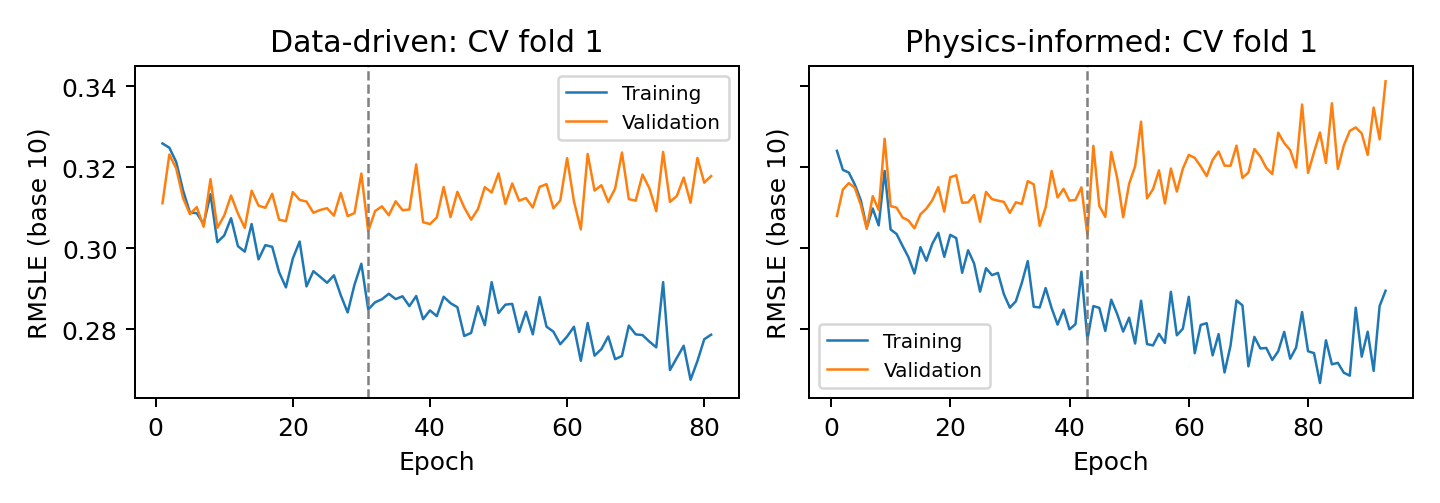

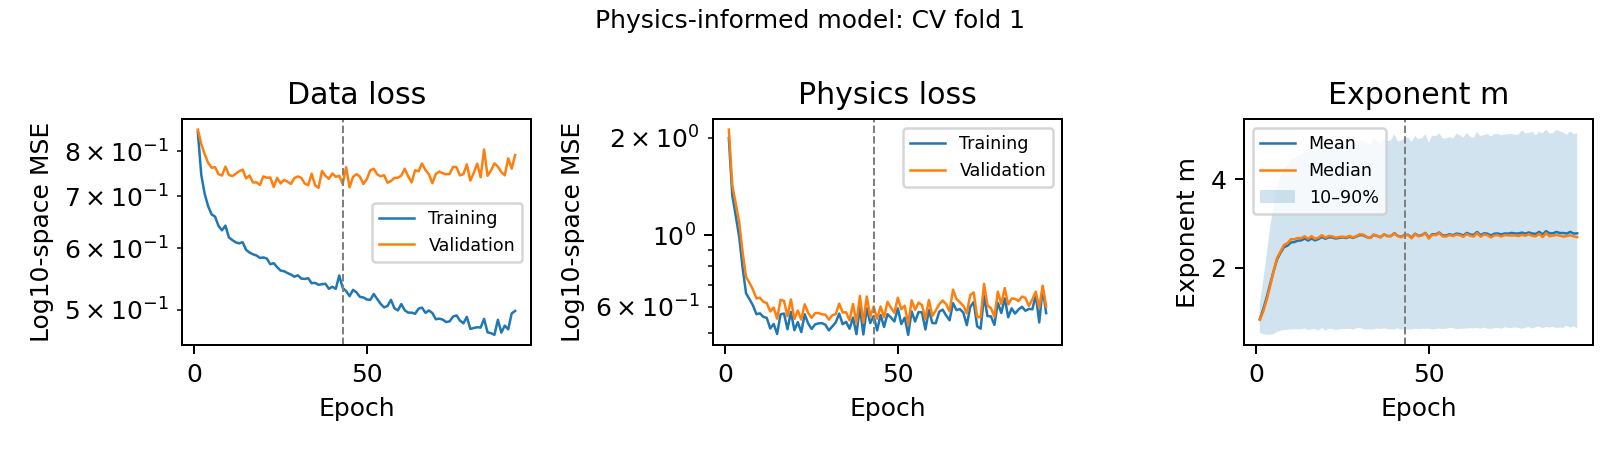

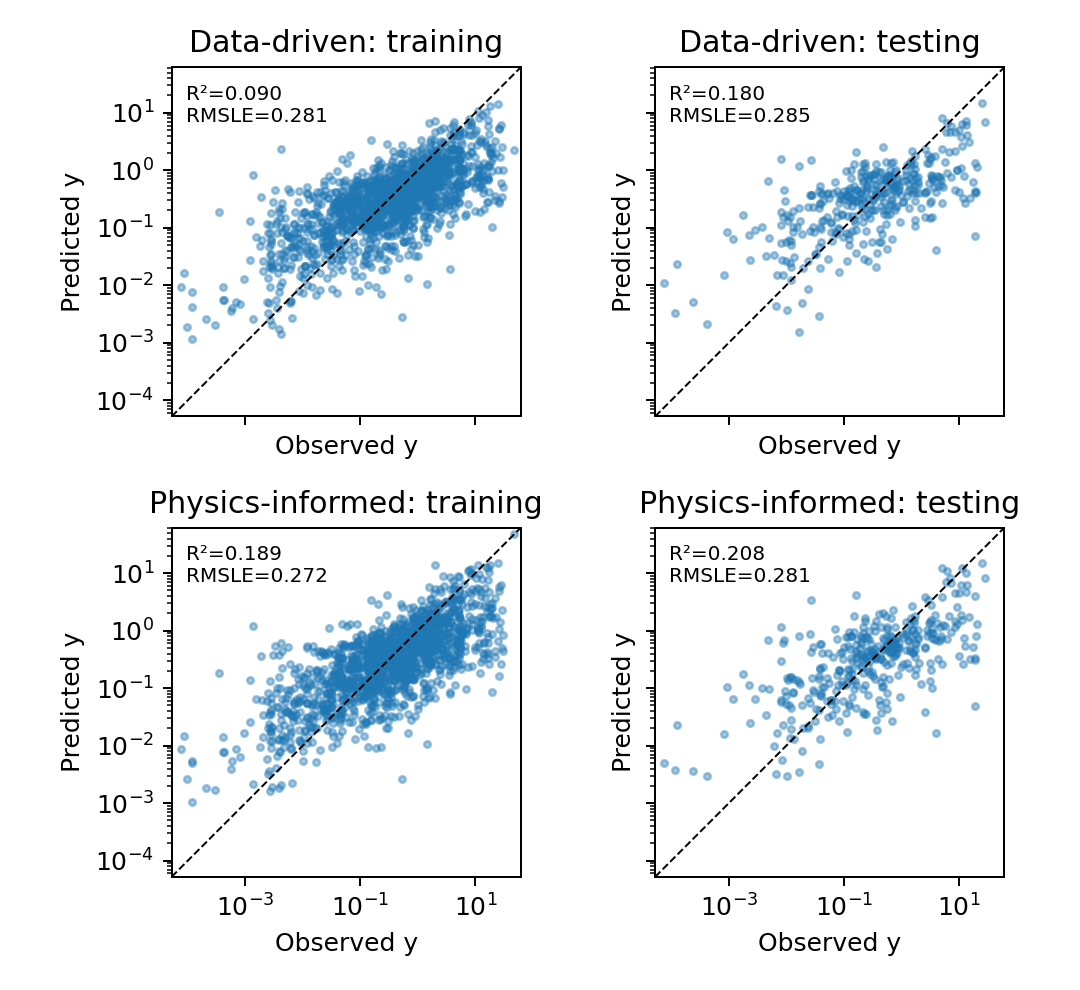

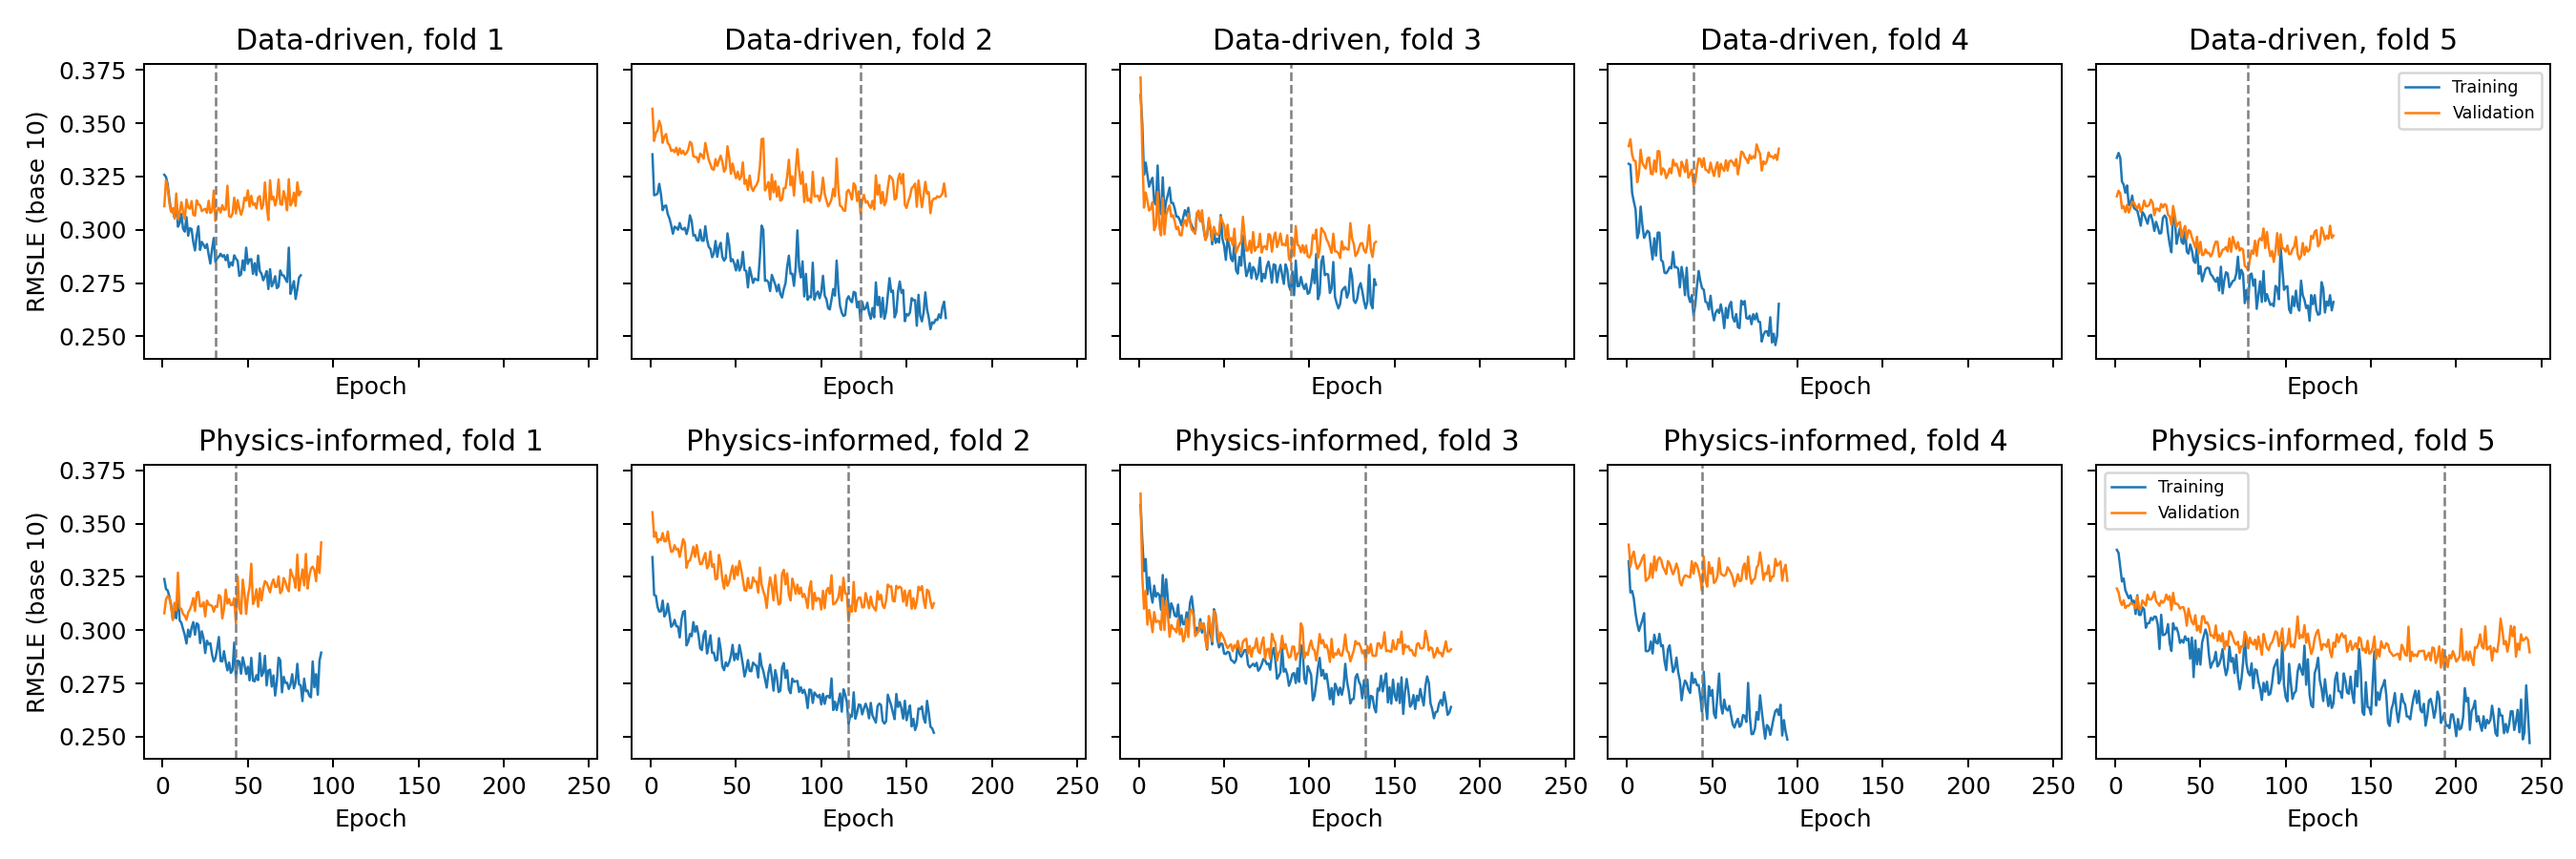

In [ ]:
from IPython.display import Image, display
for name in ["training_validation_curves.png", "physics_training_diagnostics.png",
             "observed_vs_predicted.png", "all_folds_learning_curves.png"]:
    display(Image(filename=str(FINAL_OUTPUT / "figures" / name)))


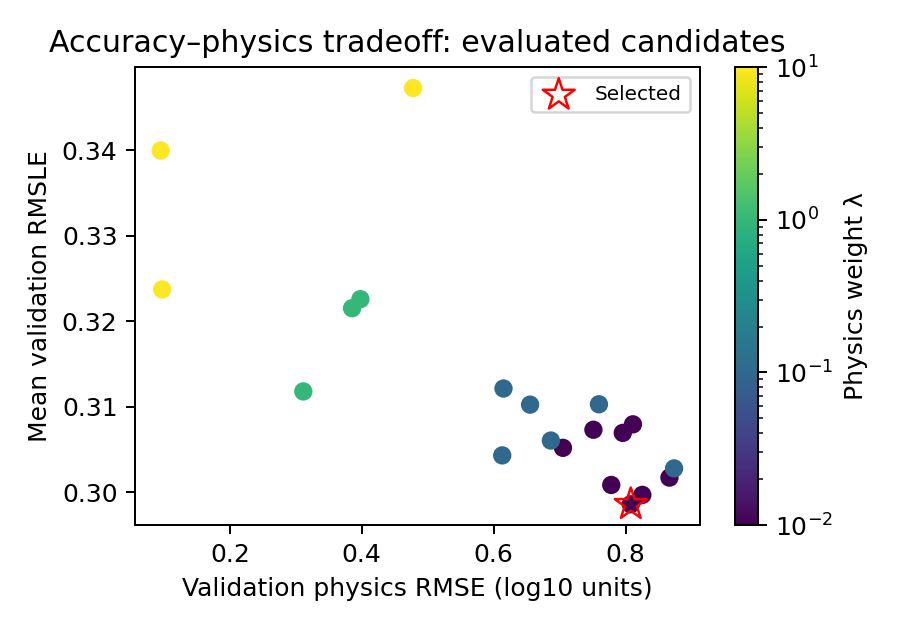

In [ ]:
display(Image(filename=str(FINAL_OUTPUT / "figures/accuracy_physics_tradeoff.png")))


## 12. Export analysis outputs
The archive contains saved partitions, configurations, search records, fold/final checkpoints, predictions linked to IDs, metrics, and figures. The separately maintained academic report is excluded. Download the archive before ending a temporary Colab runtime.


In [ ]:
import zipfile
archive = Path("challenge_progress.zip")
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for directory in [OUTPUT_ROOT, Path("configs")]:
        for path in sorted(directory.rglob("*")):
            if path.is_file():
                bundle.write(path, arcname=str(path))
print(f"Saved {archive.resolve()}")
try:
    from google.colab import files
except ImportError:
    pass
else:
    files.download(str(archive))
